# Lab 9D: GANs and Conditional GANs

## ✅ Solution version

All `???` gaps are filled in, and a **Solution and discussion** box follows every set of questions. Your own numbers will differ somewhat from run to run; what matters is whether you can explain the patterns.

**Before you start: Runtime → Change runtime type → GPU.**

This is the last of the four notebooks. The VAE in 9C gave us a latent space we can sample from, but
its samples are **blurry**. A GAN drops the reconstruction loss altogether: a second network, the
**discriminator**, learns to tell real images from generated ones, and the **generator** learns to
fool it.

The lecture explained *what* a GAN is. Training one involves a few practical details that the lecture
did not cover: how to train two networks with opposite goals, when to stop gradients, why the
generator's loss is not simply the negative of the discriminator's, and how to tell whether training
is going well. This notebook explains each of them.

| Part | You will… |
|---|---|
| 1. Training a GAN, step by step | implement the two training steps of a DCGAN, train it, and learn to read its training curves |
| 2. Why the generator's loss matters | compare the "textbook" generator loss with the one used in practice |
| 3. A conditional GAN | tell the GAN *which* digit to generate |
| 4. AE vs. VAE vs. GAN | compare the three generative models on the same scores |
| 5. Exam-style questions | check your understanding |

## Setup

In [1]:
import copy
import math
import random
import time

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


# ---- Data: 10% of the MNIST training set, and 2,000 test images (used as a validation set) ----
FRACTION = 0.1
mnist_train = torchvision.datasets.MNIST('./data', train=True, download=True)
mnist_test = torchvision.datasets.MNIST('./data', train=False, download=True)
idx = torch.randperm(len(mnist_train), generator=torch.Generator().manual_seed(0))[:int(FRACTION * len(mnist_train))]

# The whole (small) dataset fits on the GPU, so we skip the DataLoader and index tensors directly.
X_train = (mnist_train.data[idx].float() / 255).unsqueeze(1).to(device)    # (6000, 1, 28, 28), values in [0, 1]
y_train = mnist_train.targets[idx].to(device)                               # labels: used ONLY for colouring plots
X_test = (mnist_test.data[:2000].float() / 255).unsqueeze(1).to(device)    # (2000, 1, 28, 28)
y_test = mnist_test.targets[:2000].to(device)
print('X_train:', tuple(X_train.shape), ' X_test:', tuple(X_test.shape))


def batches(n, batch_size=64, shuffle=True):
    # Mini-batches of indices: the same job a DataLoader(shuffle=True) does for you.
    order = torch.randperm(n, device=device) if shuffle else torch.arange(n, device=device)
    return order.split(batch_size)


def recon_loss(x_hat, x):
    # J = (1/n) * sum_i ||x_hat_i - x_i||^2 : squared error summed over pixels, averaged over the batch
    return ((x_hat - x) ** 2).flatten(1).sum(1).mean()


def show_images(x, nrow=10, title=None, ax=None, figsize=None):
    # Show a batch of (N, 1, 28, 28) images as one grid.
    x = x.detach().float().cpu().clamp(0, 1)
    grid = torchvision.utils.make_grid(x, nrow=nrow, padding=1, pad_value=1)[0]
    if ax is None:
        plt.figure(figsize=figsize or (nrow * 0.6, (len(x) + nrow - 1) // nrow * 0.6))
        ax = plt.gca()
    ax.imshow(grid, cmap='gray', vmin=0, vmax=1)
    ax.axis('off')
    if title:
        ax.set_title(title)


# ---- The "digit judge": a small CNN classifier trained on the FULL MNIST training set ----
# We use it only to SCORE generated images (it is never used to train a generative model).
class Judge(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # 14x14
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 7x7
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10))

    def forward(self, x):
        return self.net(x)


def get_judge(path='judge.pt'):
    judge = Judge().to(device)
    try:
        judge.load_state_dict(torch.load(path, map_location=device))
        print('Loaded the judge from', path)
    except FileNotFoundError:
        set_seed(0)
        Xf = (mnist_train.data.float() / 255).unsqueeze(1).to(device)
        yf = mnist_train.targets.to(device)
        opt = torch.optim.Adam(judge.parameters(), 1e-3)
        for epoch in range(2):
            for b in batches(len(Xf), 128):
                loss = F.cross_entropy(judge(Xf[b]), yf[b])
                opt.zero_grad(); loss.backward(); opt.step()
        torch.save(judge.state_dict(), path)
    judge.eval()
    with torch.no_grad():
        acc = (judge(X_test).argmax(1) == y_test).float().mean().item()
    print(f'Judge accuracy on real test digits: {acc:.1%}')
    return judge


@torch.no_grad()
def judge_scores(images, judge):
    # confidence: mean of the judge's top softmax probability  ("does it look like *some* digit?")
    # coverage:   entropy of the predicted-class histogram / log(10)  (1.0 = all ten digits equally often,
    #             0.0 = always the same digit, i.e. no variety)
    p = F.softmax(judge(images.clamp(0, 1)), dim=1)
    confidence = p.max(1).values.mean().item()
    counts = torch.bincount(p.argmax(1), minlength=10).float()
    freq = counts / counts.sum()
    coverage = -(freq[freq > 0] * freq[freq > 0].log()).sum().item() / math.log(10)
    return {'confidence': round(confidence, 3), 'coverage': round(coverage, 3)}


def sharpness(x):
    # mean absolute difference between neighbouring pixels (see 9B): low = blurry
    dx = (x[..., :, 1:] - x[..., :, :-1]).abs().mean()
    dy = (x[..., 1:, :] - x[..., :-1, :]).abs().mean()
    return (dx + dy).item()


judge = get_judge()

# The generator ends with a tanh (outputs in [-1, 1]), so we scale the real images to [-1, 1] as well.
X_gan = X_train * 2 - 1
to_01 = lambda x: (x + 1) / 2        # back to [0, 1] for display and for the judge

Using device: cuda
X_train: (6000, 1, 28, 28)  X_test: (2000, 1, 28, 28)
Loaded the judge from judge.pt
Judge accuracy on real test digits: 98.0%


---
# Part 1 — Training a GAN, step by step

### The two networks

These are the DCGAN networks from the lecture notes (Code 4). The generator treats the noise vector
$\mathbf{z} \in \mathbb{R}^{100}$ as a $100 \times 1 \times 1$ feature map and upsamples it with
transposed convolutions: $1 \to 7 \to 14 \to 28$. The discriminator is an ordinary CNN classifier with
one output, $D(\mathbf{x}) \in (0, 1)$: the probability that $\mathbf{x}$ is a **real** image.

In [2]:
Z_DIM = 100


class Generator(nn.Module):
    def __init__(self, z_dim=Z_DIM, features=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(z_dim, features * 2, 7, 1, 0, bias=False),      # 1x1 -> 7x7
            nn.BatchNorm2d(features * 2), nn.ReLU(True),
            nn.ConvTranspose2d(features * 2, features, 4, 2, 1, bias=False),   # 7x7 -> 14x14
            nn.BatchNorm2d(features), nn.ReLU(True),
            nn.ConvTranspose2d(features, 1, 4, 2, 1, bias=False),              # 14x14 -> 28x28
            nn.Tanh())

    def forward(self, z):
        return self.net(z)


class Discriminator(nn.Module):
    def __init__(self, in_channels=1, features=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, features, 4, 2, 1, bias=False),             # 28x28 -> 14x14
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(features, features * 2, 4, 2, 1, bias=False),            # 14x14 -> 7x7
            nn.BatchNorm2d(features * 2), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(features * 2, 1, 7, 1, 0, bias=False),                   # 7x7 -> 1x1
            nn.Sigmoid())

    def forward(self, x):
        return self.net(x).view(-1)          # one probability per image


def weights_init(m):                         # the initialisation recommended in the DCGAN paper
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)


def sample_z(n):
    return torch.randn(n, Z_DIM, 1, 1, device=device)

### How do you train two networks with opposite goals?

The two networks play a game (lecture, Section 5.3):
* $D$ wants $D(\mathbf{x}) \approx 1$ for real images and $D(G(\mathbf{z})) \approx 0$ for generated ones;
* $G$ wants $D(G(\mathbf{z})) \approx 1$.

We can't minimise a single loss for both, because they want opposite things. Instead, every training
iteration consists of **two separate steps**, one per network:

| | Step 1: update $D$ | Step 2: update $G$ |
|---|---|---|
| Data | a batch of real images (label 1) **and** a batch of generated images (label 0) | a batch of generated images |
| Loss | $\mathcal{L}_D = \mathrm{BCE}(D(\mathbf{x}), 1) + \mathrm{BCE}(D(G(\mathbf{z})), 0)$ | $\mathcal{L}_G$ (see below) |
| Which parameters change | only $D$'s | only $G$'s |

This leads to three practical details.

**1. Two optimisers.** Each network gets its own optimiser, created with *only its own* parameters:
`opt_D = Adam(D.parameters())` and `opt_G = Adam(G.parameters())`. When we call `opt_D.step()`,
only $D$ is updated, even though gradients may also have been computed for $G$. If we used one
optimiser for all parameters, step 1 would also update $G$ so as to **lower $D$'s loss**, i.e. to
make the fakes *easier* to spot, the opposite of what $G$ should learn.

**2. `.detach()` in step 1.** The generated images are computed by $G$, so $\mathcal{L}_D$ depends on
$G$'s parameters through the computational graph (Lecture 3):
$\mathbf{z} \to G \to G(\mathbf{z}) \to D \to \mathcal{L}_D$. Calling `loss_D.backward()` would therefore
backpropagate all the way into $G$ and compute gradients for its parameters: wasted computation, and
these gradients would pile up in $G$'s `.grad` (Lab 6: gradients accumulate). `fake.detach()` cuts the
graph at $G(\mathbf{z})$: $D$ sees the generated images as constant inputs, like the real images. In
step 2 we must **not** detach, because there the gradient *has* to flow back through $D$ into $G$:
that is the only way $G$ learns what to change. ($D$'s parameters also get gradients in step 2, but we
don't call `opt_D.step()` there, and `opt_D.zero_grad()` clears them at the start of the next step 1.)

**3. The generator's loss ("flipping the labels").** The minimax game says that $G$ should *minimise*
$\log(1 - D(G(\mathbf{z})))$. In practice, $G$ instead *minimises* $-\log D(G(\mathbf{z}))$, which in code is
`BCE(D(fake), 1)`: the generated images are given the label **real**. Both losses push $D(G(\mathbf{z}))$
towards 1, but they give very different gradients. Early in training, $D$ easily recognises the fakes,
so $D(G(\mathbf{z})) \approx 0$. Write $D = \sigma(a)$, where $a$ is the logit before the sigmoid. Then

$$\frac{\partial}{\partial a}\log\big(1 - \sigma(a)\big) = -\sigma(a) \approx 0, \qquad
\frac{\partial}{\partial a}\big(-\log \sigma(a)\big) = -\big(1 - \sigma(a)\big) \approx -1 \quad \text{when } \sigma(a) \approx 0.$$

The first ("saturating") loss gives almost **no gradient** exactly when $G$ is bad and needs it most;
the second ("non-saturating") loss gives a strong gradient there. The plot below shows both losses as a
function of $D(G(\mathbf{z}))$. In Part 2 you will test this.

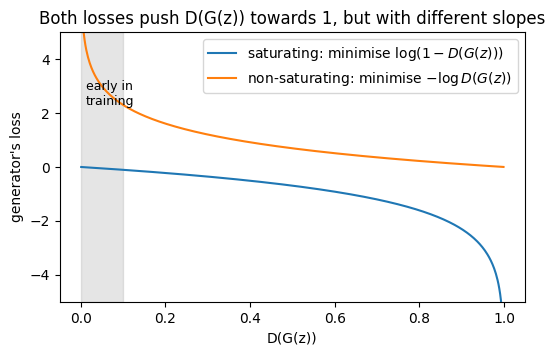

In [3]:
d = torch.linspace(0.001, 0.999, 500)
plt.figure(figsize=(6, 3.5))
plt.plot(d, torch.log(1 - d), label=r'saturating: minimise $\log(1 - D(G(z)))$')
plt.plot(d, -torch.log(d), label=r'non-saturating: minimise $-\log D(G(z))$')
plt.axvspan(0, 0.1, color='grey', alpha=0.2)
plt.text(0.012, 2.3, 'early in\ntraining', fontsize=9)
plt.xlabel('D(G(z))'); plt.ylabel("generator's loss"); plt.legend(); plt.ylim(-5, 5)
plt.title('Both losses push D(G(z)) towards 1, but with different slopes'); plt.show()

### 🛠️ TASK 1a: The discriminator step

Fill in the losses. `criterion` is `nn.BCELoss()`. The function returns some numbers that we will
monitor during training.

In [4]:
criterion = nn.BCELoss()


def d_step(G, D, opt_D, real, z, y=None):
    # One update of the discriminator. (y is only used by the conditional GAN in Part 3.)
    cond = () if y is None else (y,)
    n = len(real)
    ones, zeros = torch.ones(n, device=device), torch.zeros(n, device=device)

    opt_D.zero_grad()
    d_real = D(real, *cond)
    loss_real = criterion(d_real, ones)       # D should output 1 for real images
    fake = G(z, *cond)
    d_fake = D(fake.detach(), *cond)          # cut the graph: no gradients into G in this step
    loss_fake = criterion(d_fake, zeros)      # D should output 0 for generated images
    loss_D = loss_real + loss_fake
    loss_D.backward()
    opt_D.step()
    return {'loss_D': loss_D.item(), 'D(x)': d_real.mean().item(), 'D(G(z))': d_fake.mean().item()}

### 🛠️ TASK 1b: The generator step

Fill in the non-saturating loss (the default). The saturating version is given; we use it in Part 2.
We also record the size of $G$'s gradient (its norm), to see how strong the learning signal is.

In [5]:
def g_step(G, D, opt_G, z, y=None, saturating=False):
    # One update of the generator.
    cond = () if y is None else (y,)
    ones = torch.ones(len(z), device=device)

    opt_G.zero_grad()
    d_fake = D(G(z, *cond), *cond)            # no detach: the gradient must flow through D into G
    if saturating:
        loss_G = torch.log((1 - d_fake).clamp_min(1e-6)).mean()   # the "textbook" minimax loss (clamped to avoid log 0)
    else:
        loss_G = criterion(d_fake, ones)      # non-saturating: generated images get the label "real"
    loss_G.backward()
    grad_norm = torch.sqrt(sum((p.grad ** 2).sum() for p in G.parameters())).item()
    opt_G.step()
    return {'loss_G': loss_G.item(), 'grad_norm_G': grad_norm}

In [6]:
# Tests for Tasks 1a and 1b: each step must change ONLY its own network
def snapshot(model):
    return [p.detach().clone() for p in model.parameters()]

def changed(model, snap):
    return any(not torch.equal(p, q) for p, q in zip(model.parameters(), snap))

set_seed(0)
_G, _D = Generator().apply(weights_init).to(device), Discriminator().apply(weights_init).to(device)
_oG = torch.optim.Adam(_G.parameters(), 2e-4, betas=(0.5, 0.999))
_oD = torch.optim.Adam(_D.parameters(), 2e-4, betas=(0.5, 0.999))

_sG, _sD = snapshot(_G), snapshot(_D)
_out = d_step(_G, _D, _oD, X_gan[:64], sample_z(64))
assert changed(_D, _sD), 'd_step did not update D'
assert not changed(_G, _sG), 'd_step changed G'
assert all(p.grad is None for p in _G.parameters()), 'd_step computed gradients for G: did you detach the generated images?'
assert abs(_out['loss_D'] - 2 * math.log(2)) < 0.5, 'at initialisation, loss_D should be close to 2 log 2 = 1.39'

_sG, _sD = snapshot(_G), snapshot(_D)
_out = g_step(_G, _D, _oG, sample_z(64))
assert changed(_G, _sG), 'g_step did not update G'
assert not changed(_D, _sD), 'g_step changed D'
assert _out['loss_G'] > 0, 'the non-saturating loss -log D(G(z)) is positive'
print('✅ Tasks 1a and 1b passed')

✅ Tasks 1a and 1b passed


### Reading a GAN's training curves

In supervised learning, a falling loss means progress. In a GAN, it does not: each network's loss
depends on the *other* network, which keeps changing (a moving target). A falling $\mathcal{L}_D$ can
mean that $D$ is improving, or that $G$ has stopped improving. So we monitor:

* **$D(\mathbf{x})$ and $D(G(\mathbf{z}))$**, the discriminator's average output on real and on
  generated images. If the generator were perfect, $D$ could do no better than guessing: both would be
  0.5, giving $\mathcal{L}_D = 2\log 2 \approx 1.39$ (it is the sum of two BCE terms) and
  $\mathcal{L}_G = \log 2 \approx 0.69$. In practice, $D$ stays somewhat ahead, so expect $D(\mathbf{x})$
  above 0.5 and $D(G(\mathbf{z}))$ below it, with both curves fluctuating.
* **Warning signs**: $D(\mathbf{x}) \to 1$ and $D(G(\mathbf{z})) \to 0$ with $\mathcal{L}_D \to 0$ means that
  $D$ has won, and $G$'s gradient may vanish. Wild oscillations mean non-convergence.
* **Mode collapse** is invisible in the losses. We detect it with the judge's **coverage**, and by
  looking at samples generated from the **same fixed noise vectors** throughout training (so that
  changes in the pictures are caused by training, not by new noise).

We train for 25 epochs (about 2,300 steps of each network) with the settings from the DCGAN paper
(Adam, lr = 2e-4, $\beta_1 = 0.5$).

epoch   1   loss_D 0.21   loss_G 3.02   {'confidence': 0.537, 'coverage': 0.297, 'sharpness': 0.97}
epoch   5   loss_D 0.19   loss_G 2.74   {'confidence': 0.679, 'coverage': 0.92, 'sharpness': 1.13}
epoch  10   loss_D 0.37   loss_G 2.28   {'confidence': 0.758, 'coverage': 0.942, 'sharpness': 1.06}
epoch  15   loss_D 0.59   loss_G 1.86   {'confidence': 0.804, 'coverage': 0.942, 'sharpness': 1.07}
epoch  20   loss_D 0.54   loss_G 2.03   {'confidence': 0.822, 'coverage': 0.968, 'sharpness': 1.01}
epoch  25   loss_D 0.75   loss_G 1.95   {'confidence': 0.834, 'coverage': 0.969, 'sharpness': 1.03}
Training time: 27 s


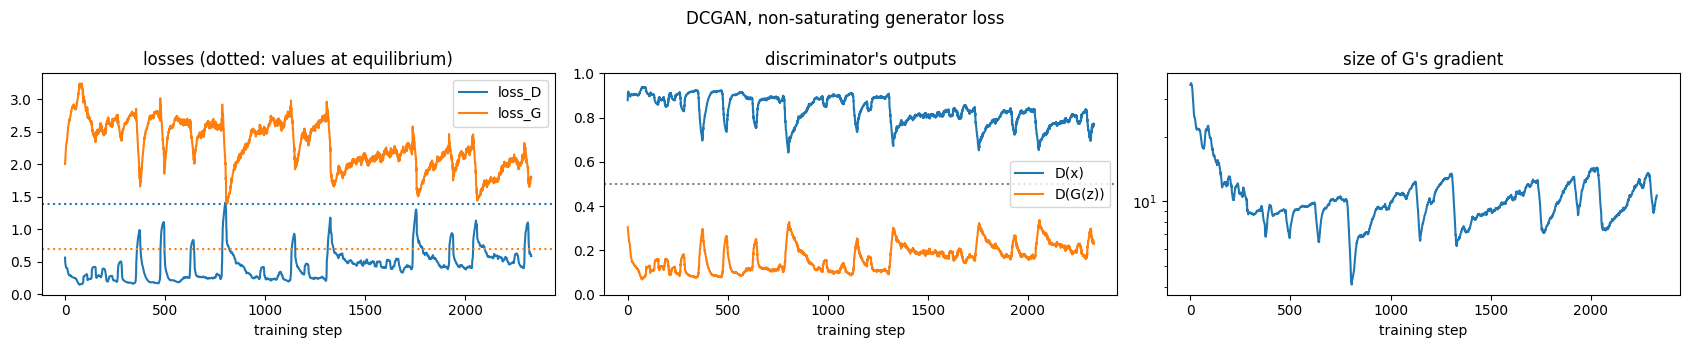

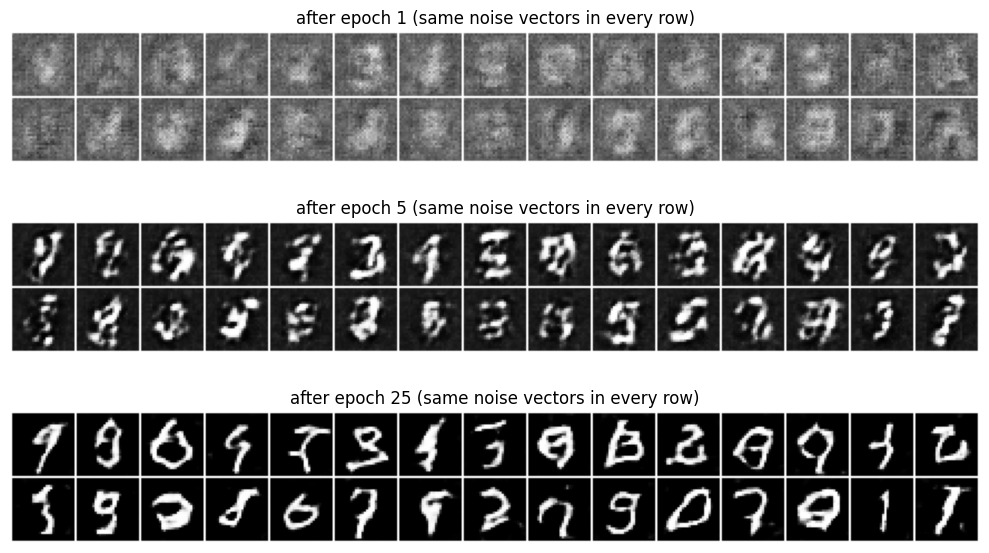

In [7]:
@torch.no_grad()
def evaluate_G(G, z, y=None):
    G.eval()
    x = to_01(G(z) if y is None else G(z, y))
    G.train()
    scores = judge_scores(x, judge)
    scores['sharpness'] = round(sharpness(x) / sharpness(X_test), 2)
    return scores, x


def train_gan(epochs=25, saturating=False, seed=0, eval_every=5, show_epochs=(1, 5, 25)):
    set_seed(seed)
    G, D = Generator().apply(weights_init).to(device), Discriminator().apply(weights_init).to(device)
    opt_G = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
    opt_D = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
    z_fixed = sample_z(2000)
    log, evals, snapshots = [], {}, {}
    for epoch in range(1, epochs + 1):
        for b in batches(len(X_gan), 64):
            out = d_step(G, D, opt_D, X_gan[b], sample_z(len(b)))
            out.update(g_step(G, D, opt_G, sample_z(len(b)), saturating=saturating))
            log.append(out)
        if epoch % eval_every == 0 or epoch in show_epochs:
            evals[epoch], x = evaluate_G(G, z_fixed)
            if epoch in show_epochs:
                snapshots[epoch] = x[:30]
            print(f'epoch {epoch:3d}   loss_D {np.mean([l["loss_D"] for l in log[-50:]]):.2f}   '
                  f'loss_G {np.mean([l["loss_G"] for l in log[-50:]]):.2f}   {evals[epoch]}')
    return G, D, log, evals, snapshots


def plot_log(log, title=''):
    k = 20                                                                  # moving average over 20 steps
    smooth = lambda v: np.convolve(v, np.ones(k) / k, mode='valid')
    fig, axs = plt.subplots(1, 3, figsize=(17, 3.5))
    for key in ['loss_D', 'loss_G']:
        axs[0].plot(smooth([l[key] for l in log]), label=key)
    axs[0].axhline(2 * math.log(2), ls=':', c='C0'); axs[0].axhline(math.log(2), ls=':', c='C1')
    axs[0].set_title('losses (dotted: values at equilibrium)'); axs[0].legend()
    for key in ['D(x)', 'D(G(z))']:
        axs[1].plot(smooth([l[key] for l in log]), label=key)
    axs[1].axhline(0.5, ls=':', c='grey'); axs[1].set_ylim(0, 1); axs[1].set_title("discriminator's outputs"); axs[1].legend()
    axs[2].semilogy(smooth([l['grad_norm_G'] for l in log])); axs[2].set_title("size of G's gradient")
    for ax in axs:
        ax.set_xlabel('training step')
    fig.suptitle(title); plt.tight_layout(); plt.show()


t0 = time.time()
G, D, log, evals, snapshots = train_gan()
print(f'Training time: {time.time() - t0:.0f} s')
plot_log(log, 'DCGAN, non-saturating generator loss')
fig, axs = plt.subplots(len(snapshots), 1, figsize=(10, 2 * len(snapshots)))
for ax, (epoch, x) in zip(axs, snapshots.items()):
    show_images(x, nrow=15, ax=ax, title=f'after epoch {epoch} (same noise vectors in every row)')
plt.tight_layout(); plt.show()

### Questions 1

1. Describe the curves of $D(\mathbf{x})$ and $D(G(\mathbf{z}))$. Did training reach the equilibrium
   value 0.5? Who is "winning"?
2. The losses fluctuate and do not steadily decrease. Why is that not a sign that training failed?
   What tells you that the generator *did* improve?
3. Compare the sample rows for epochs 1, 5 and 25. What does the generator learn first, and what later?
4. Is there any sign of mode collapse? Which number and which picture tell you?
5. Why do we need the judge at all here, rather than just the losses?

> ### ✅ Solution and discussion
> 1. $D(\mathbf{x})$ stays well above 0.5 and $D(G(\mathbf{z}))$ well below (in the reference run roughly 0.8–0.9 and
>    0.1–0.3, with sudden jumps where the generator briefly "catches up"): the discriminator stays ahead, as
>    is typical, but it has not "won" (it does not reach 1 and 0), and the size of G's gradient stays roughly
>    constant, so the generator keeps getting a useful learning signal. The equilibrium of 0.5 is a
>    theoretical limit that is rarely reached in practice.
> 2. Each loss measures how well one network does *against the current version of the other*, and both keep
>    changing, so there is no fixed target to converge to. Progress is visible in the samples and in the
>    judge's scores, which improve over the epochs (in the reference run confidence 0.54 after 1 epoch, 0.68 after 5 and
>    0.83 after 25), while the losses look much the same.
> 3. After epoch 1: blobs with roughly the right brightness and position. After epoch 5: digit-like strokes,
>    but many malformed shapes. After 25 epochs: mostly clear, sharp digits, with some failures. The
>    generator learns the coarse layout first and the details later. Because the noise is fixed, the same
>    position in each row shows how one sample evolves.
> 4. No clear sign: the coverage stays high (0.97 in the reference run, close to the 0.997 for real digits), and the
>    samples show all digits in many styles. With mode collapse, the coverage would drop and the rows would
>    show the same few digits repeated.
> 5. The losses only tell us about the balance between $G$ and $D$, not about the quality or variety of the
>    images. The judge gives an independent measure of both (and we still look at the samples).

---
# Part 2 — Why the generator's loss matters

We train the same GAN, with the same seed, for 5 epochs using the **saturating** loss
$\log(1 - D(G(\mathbf{z})))$, and compare it with the first 5 epochs of the run above.

✍️ **Prediction:** what will happen to the size of $G$'s gradient, to $D(G(\mathbf{z}))$, and to the
samples?

epoch   5   loss_D 0.54   loss_G -0.18   {'confidence': 0.582, 'coverage': 0.645, 'sharpness': 0.97}


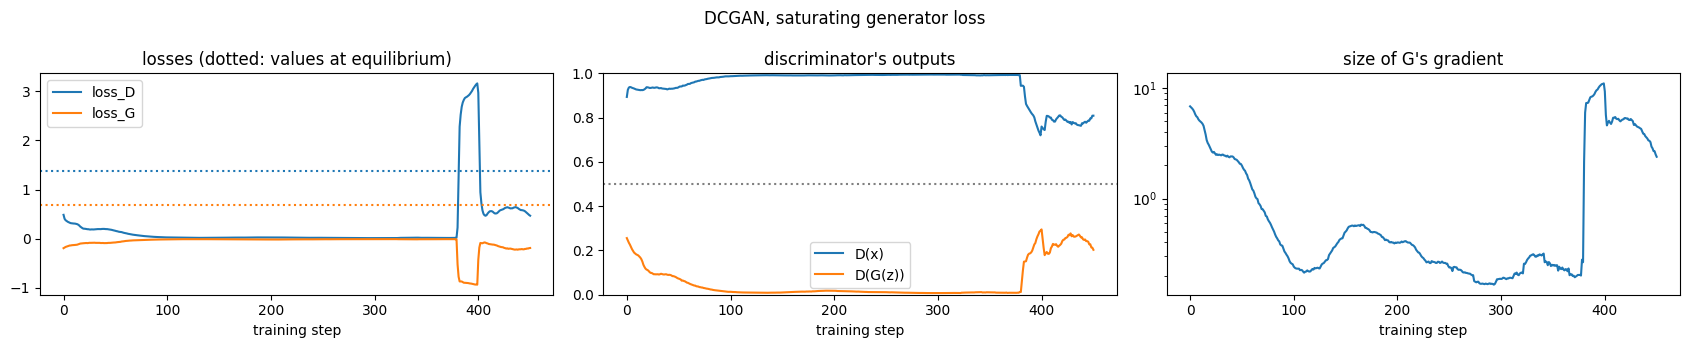

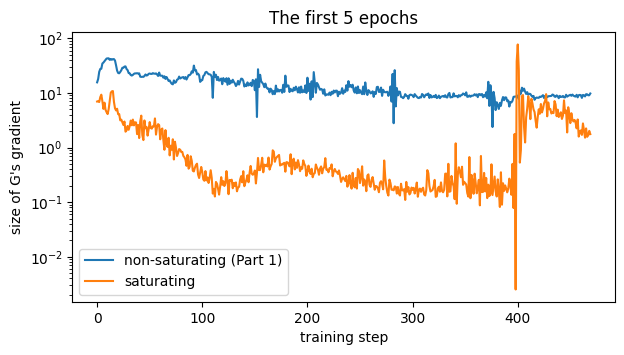

after 5 epochs, non-saturating: {'confidence': 0.679, 'coverage': 0.92, 'sharpness': 1.13}
after 5 epochs, saturating:     {'confidence': 0.582, 'coverage': 0.645, 'sharpness': 0.97}


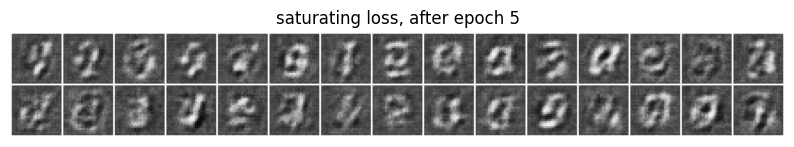

In [8]:
G_sat, D_sat, log_sat, evals_sat, snaps_sat = train_gan(epochs=5, saturating=True, show_epochs=(5,))
plot_log(log_sat, 'DCGAN, saturating generator loss')

n = len(log_sat)
plt.figure(figsize=(7, 3.5))
plt.semilogy([l['grad_norm_G'] for l in log[:n]], label='non-saturating (Part 1)')
plt.semilogy([l['grad_norm_G'] for l in log_sat], label='saturating')
plt.xlabel('training step'); plt.ylabel("size of G's gradient"); plt.legend(); plt.title('The first 5 epochs'); plt.show()

print('after 5 epochs, non-saturating:', evals[5])
print('after 5 epochs, saturating:    ', evals_sat[5])
show_images(snaps_sat[5], nrow=15, title='saturating loss, after epoch 5', figsize=(10, 1.5))

### Questions 2

1. **Mechanism:** compare the size of $G$'s gradient in the two runs. Does it match the explanation in
   Part 1?
2. **Outcome:** compare the samples and the scores after 5 epochs. What happened to $D(\mathbf{x})$,
   $D(G(\mathbf{z}))$ and $\mathcal{L}_D$ in the saturating run, and why does that stop the generator
   from learning?
3. Both losses have the same goal ($D(G(\mathbf{z})) \to 1$). Why then do they behave so differently?

> ### ✅ Solution and discussion
> 1. Yes. In the saturating run the gradient shrinks by one to two orders of magnitude within the first
>    ~100 steps (in the reference run to about 0.2–0.5, against about 10 for the non-saturating loss), exactly when
>    $D(G(\mathbf{z}))$ drops towards 0.
> 2. In the saturating run the discriminator wins: for a long stretch (in the reference run the first ~380 steps)
>    $D(\mathbf{x}) \approx 1$, $D(G(\mathbf{z})) \approx 0$ and $\mathcal{L}_D \approx 0$. Once
>    $D(G(\mathbf{z})) \approx 0$, the saturating loss is flat, so $G$ gets almost no gradient and improves
>    only slowly, which lets $D$ stay certain: a vicious circle. This is the "diminished gradient" failure
>    mode from the lecture. Depending on the random path, the generator may eventually escape (in the reference
>    run there is a sudden jump around step 380), but it has lost most of the 5 epochs: its samples are smudgy
>    shapes on a grey background (confidence 0.58 and coverage 0.65, against 0.68 and 0.92 for the
>    non-saturating run).
>    In other runs it never escapes within 5 epochs. Note that the sharpness score is high for these samples
>    too: noise also has large differences between neighbouring pixels, so sharpness only means something
>    for images that already look like digits.
> 3. Gradient descent only uses the **slope** of the loss, not its goal. In the region where training
>    starts ($D(G(\mathbf{z})) \approx 0$), the saturating loss is almost flat and the non-saturating loss is
>    steep. This is why GAN implementations use the "flipped labels" for the generator.

---
# Part 3 — A conditional GAN

Our GAN generates random digits; we cannot ask it for a 3. A **conditional GAN** (lecture, Section 5.4)
gives the label $y$ to **both** networks:

* the **generator** gets $\mathbf{z}$ and a one-hot vector for $y$, concatenated: a $(100 + 10) \times 1 \times 1$ input;
* the **discriminator** gets the image and the label. Since the discriminator's input is an image,
  we turn the one-hot vector into **10 extra input channels**: channel $k$ is a constant 28×28 image
  that is 1 if $y = k$ and 0 otherwise. The first convolution then has $1 + 10$ input channels.

This is the same idea as the input surgery in Lab 8 (more input channels) and as feeding metadata to a
network: information that is not an image can be given to a CNN as extra constant channels. The
discriminator now judges whether an image is a **real example of digit $y$**, so the generator has to
produce the requested digit to fool it.

### 🛠️ TASK 3a: Feed the label to both networks

In [9]:
class CondGenerator(Generator):
    def __init__(self):
        super().__init__(z_dim=Z_DIM + 10)                  # the first layer gets 110 input channels

    def forward(self, z, y):
        y_onehot = F.one_hot(y, 10).float().view(-1, 10, 1, 1)     # (N, 10, 1, 1)
        return self.net(torch.cat([z, y_onehot], dim=1))           # concatenate z and the one-hot label


class CondDiscriminator(Discriminator):
    def __init__(self):
        super().__init__(in_channels=1 + 10)                # the image plus 10 label channels

    def forward(self, x, y):
        y_maps = F.one_hot(y, 10).float().view(-1, 10, 1, 1).expand(-1, 10, 28, 28)   # (N, 10, 28, 28)
        return self.net(torch.cat([x, y_maps], dim=1)).view(-1)    # concatenate the image and the label maps

In [10]:
# Test for Task 3a
_cG, _cD = CondGenerator().to(device), CondDiscriminator().to(device)
_y = torch.arange(10, device=device)
_x = _cG(sample_z(10), _y)
assert _x.shape == (10, 1, 28, 28), f'generator output has shape {tuple(_x.shape)}'
_p = _cD(_x, _y)
assert _p.shape == (10,) and 0 < _p.min() and _p.max() < 1
print('✅ Task 3a passed')

✅ Task 3a passed


### Train the conditional GAN

The training loop is the same as before, but the real images now come with their labels, and the
generated images are generated for random labels. `d_step` and `g_step` already pass `y` on to the
networks.

Besides confidence and coverage, we now measure **label accuracy**: how often the judge recognises the
digit that we asked for.

✍️ **Prediction:** will the label accuracy be close to the judge's accuracy on real digits (≈ 98%)?

epoch   5   {'confidence': 0.836, 'coverage': 0.965, 'sharpness': 1.12}   label accuracy 67.8%
epoch  10   {'confidence': 0.921, 'coverage': 0.995, 'sharpness': 1.07}   label accuracy 86.6%
epoch  15   {'confidence': 0.939, 'coverage': 0.997, 'sharpness': 1.05}   label accuracy 89.0%
epoch  20   {'confidence': 0.954, 'coverage': 0.999, 'sharpness': 1.05}   label accuracy 93.1%
epoch  25   {'confidence': 0.96, 'coverage': 0.999, 'sharpness': 1.05}   label accuracy 93.8%
Training time: 35 s


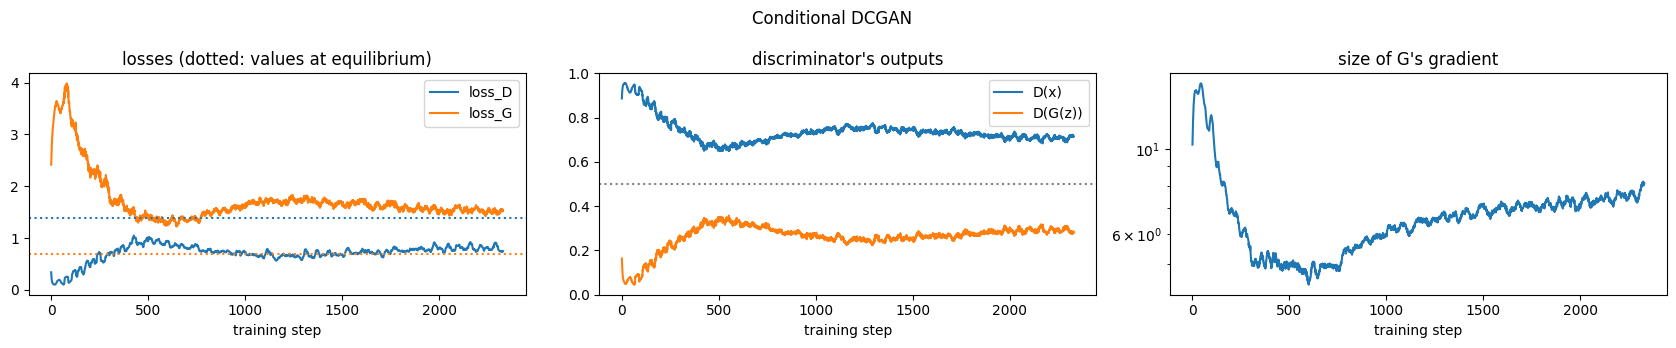

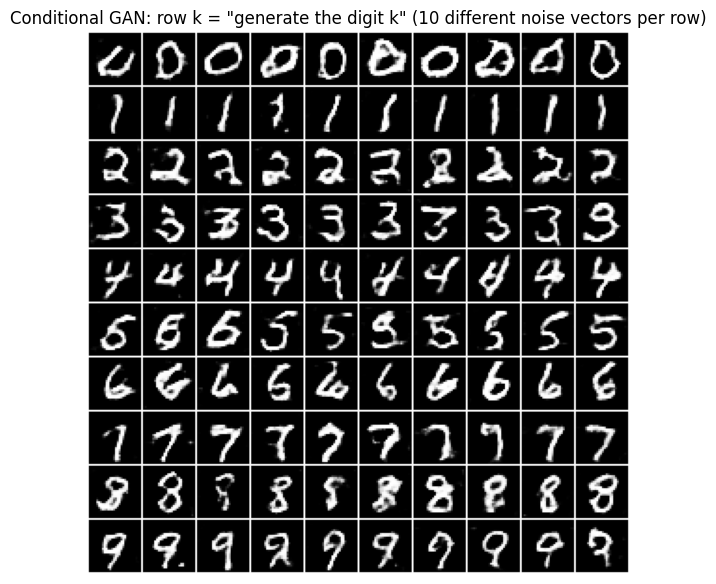

In [11]:
set_seed(0)
cG, cD = CondGenerator().apply(weights_init).to(device), CondDiscriminator().apply(weights_init).to(device)
opt_cG = torch.optim.Adam(cG.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_cD = torch.optim.Adam(cD.parameters(), lr=2e-4, betas=(0.5, 0.999))
z_eval, y_eval = sample_z(2000), torch.arange(10, device=device).repeat(200)


@torch.no_grad()
def label_accuracy(G):
    G.eval()
    pred = judge(to_01(G(z_eval, y_eval))).argmax(1)
    G.train()
    return (pred == y_eval).float().mean().item()


t0 = time.time()
clog = []
for epoch in range(1, 26):
    for b in batches(len(X_gan), 64):
        y_fake = torch.randint(0, 10, (len(b),), device=device)
        out = d_step(cG, cD, opt_cD, X_gan[b], sample_z(len(b)), y=y_train[b])    # real images WITH their labels
        out.update(g_step(cG, cD, opt_cG, sample_z(len(b)), y=y_fake))
        clog.append(out)
    if epoch % 5 == 0:
        scores, _ = evaluate_G(cG, z_eval, y_eval)
        print(f'epoch {epoch:3d}   {scores}   label accuracy {label_accuracy(cG):.1%}')
print(f'Training time: {time.time() - t0:.0f} s')
plot_log(clog, 'Conditional DCGAN')

cG.eval()
with torch.no_grad():
    grid = to_01(cG(sample_z(100), torch.arange(10, device=device).repeat_interleave(10)))
cG.train()
show_images(grid, nrow=10, title='Conditional GAN: row k = "generate the digit k" (10 different noise vectors per row)', figsize=(7, 7.5))

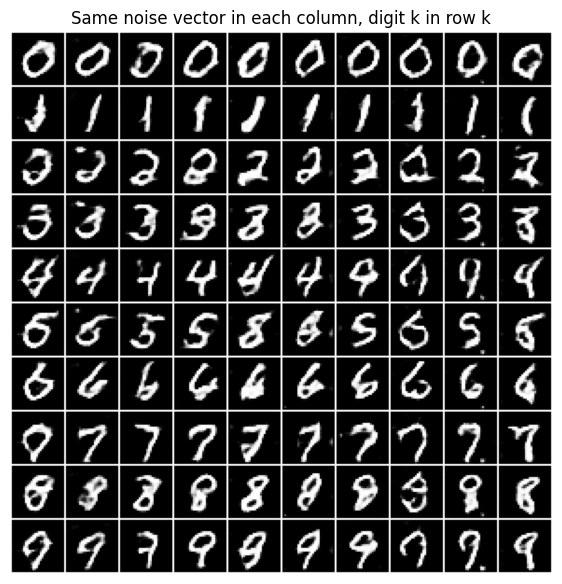

In [12]:
# The same 10 noise vectors (columns) for every digit (rows): what does z control when y is fixed?
cG.eval()
with torch.no_grad():
    z10 = sample_z(10)
    grid = to_01(cG(z10.repeat(10, 1, 1, 1), torch.arange(10, device=device).repeat_interleave(10)))
cG.train()
show_images(grid, nrow=10, title='Same noise vector in each column, digit k in row k', figsize=(7, 7.5))

### Questions 3

1. Did the generator learn to produce the requested digit? Use the label accuracy and the first grid.
2. Look at the second grid (same noise vector in each column). What does the noise vector $\mathbf{z}$
   control, once the label is fixed?
3. Why must the label also be given to the **discriminator**? What could the generator get away with
   if only the generator received $y$?
4. **Project perspective:** you could use a conditional GAN to generate extra training images for a
   rare class in your project. What could go wrong? How would you check whether it helps?

> ### ✅ Solution and discussion
> 1. Yes: the rows show the requested digits, and the label accuracy rises during training (in the reference run
>    from 68% after 5 epochs to 94% after 25), somewhat below the judge's 98% on real digits, because some samples are
>    malformed or ambiguous (e.g. 4/9, 3/5).
> 2. The **style**: thickness, slant, width and other properties that are shared across the digits in a
>    column. The label determines *what* is drawn, the noise *how* it is drawn. This separation emerges
>    without being asked for.
> 3. If $D$ does not see the label, it only checks whether the image is a realistic digit, *any* digit. The
>    generator could then ignore $y$ and still fool $D$. With the label, a perfectly drawn 7 labelled "3" is
>    an easy fake for $D$, so $G$ is forced to respect the label.
> 4. Generated images can be wrong or unrealistic in ways that are hard to see (wrong label, artefacts,
>    missing rare variations), and a GAN trained on few examples of the rare class cannot produce more
>    variety than it has seen; it may even reproduce the training images (memorisation), which adds no new
>    information. Check it as a controlled experiment (Lab 7): the same classifier trained with and without
>    the generated images, evaluated on **real** validation data only, with several seeds.

---
# Part 4 — AE vs. VAE vs. GAN

Fill in the numbers from 9C (the AE with the fitted Gaussian, and the VAE with β = 1); the GAN and the
conditional GAN are printed below.

In [13]:
scores_cgan, _ = evaluate_G(cG, z_eval, y_eval)
print('GAN (25 epochs):            ', evals[25])
print('conditional GAN (25 epochs):', scores_cgan, f'label accuracy {label_accuracy(cG):.1%}')
print('real test digits:           ', judge_scores(X_test, judge), '(sharpness 1.0 by definition)')

GAN (25 epochs):             {'confidence': 0.834, 'coverage': 0.969, 'sharpness': 1.03}
conditional GAN (25 epochs): {'confidence': 0.96, 'coverage': 0.999, 'sharpness': 1.05} label accuracy 93.8%
real test digits:            {'confidence': 0.979, 'coverage': 0.997} (sharpness 1.0 by definition)


| Model | Confidence | Coverage | Sharpness | Can encode an image? | Can choose the digit? |
|---|---|---|---|---|---|
| AE + fitted Gaussian (9C) | | | | | |
| VAE, β = 1 (9C) | | | | | |
| GAN | | | | | |
| Conditional GAN | | | | | |

### Questions 4

1. Which model generates the best images according to the scores? Is that also your impression from
   looking at the samples?
2. The GAN has no encoder. What can you do with an AE or a VAE that you cannot do with this GAN?
3. Which model was the hardest to train? Think about what you needed in Parts 1 and 2 that you did not
   need for the VAE.
4. Fill in the lecture's summary in your own words: for each model, one strength and one weakness, based
   on what you have **measured** in 9A–9D.

> ### ✅ Solution and discussion
> 1. In the reference runs the GAN had a better confidence (0.83 vs. 0.78 for the VAE) and coverage (0.97 vs.
>    0.92), and the only sharpness close to that of real digits (1.03 vs. 0.63). The conditional GAN was
>    better still (confidence 0.96, coverage 0.999): knowing the label makes the generator's job easier,
>    and we choose the labels evenly. The samples agree: GAN digits are crisp, VAE digits are blurry. (Note
>    that the VAE had a 2D latent space and the GAN 100 dimensions, so this is not a perfectly controlled
>    comparison.)
> 2. Encode a given image: find its latent code, reconstruct it, interpolate between two *specific*
>    images, denoise it, or use the code as a feature vector. A GAN only maps noise to images.
> 3. The GAN: two networks, two optimisers, `.detach()`, the non-saturating loss, a special initialisation,
>    specific Adam settings, and losses that do not tell you whether training works. The VAE is trained by
>    minimising one loss with ordinary gradient descent.
> 4. For example: AE: good reconstructions and features; no usable sampling distribution. VAE: smooth,
>    structured latent space that you can sample from; blurry samples. GAN: sharp samples; unstable,
>    tricky training and no encoder. Conditional GAN: control over the class; needs labels. (Lecture 13 adds
>    diffusion models, which combine stable training with high-quality samples.)

---
# Part 5 — Exam-style questions

**Q1.** In the discriminator's training step, the generated images are passed through `.detach()`. Why?

* (a) To make the generated images look more realistic.
* (b) So that the discriminator's loss is not backpropagated into the generator.
* (c) Because the discriminator cannot process images that require gradients.
* (d) To convert the images to the range [0, 1].

**Q2.** In the generator's training step, `criterion(D(G(z)), real_labels)` is used. What does this achieve?

* (a) It trains the discriminator to label generated images as real.
* (b) It minimises $-\log D(G(\mathbf{z}))$, which pushes $D(G(\mathbf{z}))$ towards 1 and gives strong gradients even when $D(G(\mathbf{z})) \approx 0$.
* (c) It is equivalent to the reconstruction loss of an autoencoder.
* (d) It prevents mode collapse.

**Q3.** During GAN training, $D(\mathbf{x}) \to 1$, $D(G(\mathbf{z})) \to 0$ and the discriminator's loss goes to 0. What is the most likely problem?

* (a) The generator has become perfect.
* (b) The discriminator dominates, and the generator's gradient vanishes.
* (c) Mode collapse.
* (d) The learning rate of the generator is too high.

**Q4.** How does a conditional GAN differ from a standard GAN?

* (a) It uses a reconstruction loss.
* (b) Both the generator and the discriminator receive the class label as an extra input.
* (c) Only the discriminator receives the class label.
* (d) It has an encoder that maps images to latent vectors.

> ### ✅ Solution and discussion
> * **Q1: (b).** (It also saves computation.)
> * **Q2: (b).**
> * **Q3: (b).** (a) would give $D(\mathbf{x}) \approx D(G(\mathbf{z})) \approx 0.5$. Mode collapse (c) is not visible in these numbers.
> * **Q4: (b).** See Question 3.3 for why the discriminator needs it too.

---
**That's it for Lab 9.** Complete this week's pages in your **iteration log**.